<a href="https://colab.research.google.com/github/LikithaSrinivasa25/ml-dl-algorithms/blob/main/nlp/nmf_nlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install advertools -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.1/310.1 KB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.9/272.9 KB 17.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 40.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.4/261.4 KB 11.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 57.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 KB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.9/93.9 KB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.6/74.6 KB 5.8 MB/s eta 0:00:00


In [ ]:
!pip install contractions -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.5/287.5 KB 6.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.5/104.5 KB 9.9 MB/s eta 0:00:00


In [ ]:
!pip install clean-text -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 KB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.4/175.4 KB 7.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import pandas as pd
import nltk
import numpy as np
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import advertools as adv
import re
import contractions
from cleantext import clean
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from wordcloud import WordCloud

In [ ]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
class Preprocess:

  def __init__(self,text):
    self.ltext=text.lower()
    self.text=contractions.fix(self.ltext)
    self.stop_words=set(adv.stopwords['english'])

  def emoji(self):
    e_txt=clean(self.text, no_emoji=True)
    return e_txt

  def remove_quotes_brackets(self,text):
    self.text1=re.sub("[\"\'\(\)]", "", text)
    return self.text1

  def remove_punctuations(self,text):
    text1=re.sub(r"[^\w\s]", " ",text)
    return text1

  def remove_digits(self,text):
    dtext = re.sub(r'\d', '', text)
    return dtext

  def tokenize(self,text):
    self.t_text=word_tokenize(text)
    return self.t_text

  def stop_word(self,text):
    self.sw=[]
    for i in text:
      if i not in self.stop_words:
        self.sw.append(i)
    return self.sw

  def lemma(self,text):
    lst=[]
    lemmatizer = WordNetLemmatizer()
    for i in text:
      lst.append(lemmatizer.lemmatize(i))
    return lst

  def preprocess(self):
    e_txt=self.emoji()
    q_text=self.remove_quotes_brackets(e_txt)
    p_text=self.remove_punctuations(q_text)
    d_text=self.remove_digits(p_text)
    t_text=self.tokenize(d_text)
    swtext=self.stop_word(t_text)
    l_text=self.lemma(swtext)
    word=' '.join(swtext)
    return word


In [ ]:
txt1='''Amul hikes milk prices, new rates effective from today.'''

In [ ]:
txt2='''Jupiter becomes king of moons: 12 new moons found around biggest planet in Solar System.'''

In [ ]:
txt3='''Irfan Pathan backs Prithvi Shaw to open for Team India,Need to give him a long run.'''

In [ ]:
txt4='''Sadghuru 's Latest Investment Has Experts in Awe And Big Banks Terrified.'''

In [ ]:
txt5='''Shah Rukh Khan pens a sweet birthday note for Pathaan co-star Deepika Padukone, drops a new poster'''

In [ ]:
txt6=''''You'll be deeply missed!' Mahesh Babu, Mohanlal and Ilaiyaraaja pay last respects to K Viswanath.'''

In [ ]:
txt7='''Australian Open clocks record attendance despite schedule disruptions due to rain'''

In [ ]:
d={}
j=1
for i in (txt1,txt2,txt3,txt4,txt5,txt5,txt6,txt7):
  p=Preprocess(i)
  l=p.preprocess()
  d[j]=l
  j+=1
print(d)

{1: 'amul hikes milk prices new rates effective today', 2: 'jupiter king moons new moons found biggest planet solar system', 3: 'irfan pathan backs prithvi shaw open team india need long run', 4: 'sadghuru s latest investment experts awe big banks terrified', 5: 'shah rukh khan pens sweet birthday note pathaan co star deepika padukone drops new poster', 6: 'shah rukh khan pens sweet birthday note pathaan co star deepika padukone drops new poster', 7: 'deeply missed mahesh babu mohanlal ilaiyaraaja pay respects k viswanath', 8: 'australian open clocks record attendance despite schedule disruptions rain'}


In [ ]:
df=pd.DataFrame(list(d.items()),columns=['document','text'])
df.set_index('document')

,text
document,
1,amul hikes milk prices new rates effective today
2,jupiter king moons new moons found biggest pla...
3,irfan pathan backs prithvi shaw open team indi...
4,sadghuru s latest investment experts awe big b...
5,shah rukh khan pens sweet birthday note pathaa...
6,shah rukh khan pens sweet birthday note pathaa...
7,deeply missed mahesh babu mohanlal ilaiyaraaja...
8,australian open clocks record attendance despi...


In [ ]:
tf=TfidfVectorizer()

In [ ]:
tfidf=tf.fit_transform(df['text'])

In [ ]:
vocab_tfidf=tf.get_feature_names_out()

In [ ]:
nmf_model=NMF(4)
nmf_top=nmf_model.fit_transform(tfidf)

In [ ]:
dt={}
t={}
print('The percentage of a document belonging to each topic ')
for doc in range(len(nmf_top)):
  print(f'\nDocument {doc+1}\n')
  for i,topic in enumerate(nmf_top[doc]):
    print("Topic",i+1,":",round(topic*100,2),"%")
    t[i+1]=round(topic*100,2)
    Keymax = max(t, key= lambda x: t[x])
    dt[doc+1]=Keymax


print('\nThe documents belong to these topics\n')
for i in range(len(dt)):
  print(f'Document {i+1} ---> Topic {dt[i+1]}')

The percentage of a document belonging to each topic 

Document 1

Topic 1 : 0.4 %
Topic 2 : 0.0 %
Topic 3 : 62.65 %
Topic 4 : 0.0 %

Document 2

Topic 1 : 0.0 %
Topic 2 : 0.0 %
Topic 3 : 63.03 %
Topic 4 : 0.0 %

Document 3

Topic 1 : 0.0 %
Topic 2 : 61.46 %
Topic 3 : 0.0 %
Topic 4 : 0.0 %

Document 4

Topic 1 : 0.0 %
Topic 2 : 0.13 %
Topic 3 : 0.48 %
Topic 4 : 5.15 %

Document 5

Topic 1 : 74.96 %
Topic 2 : 0.0 %
Topic 3 : 0.0 %
Topic 4 : 0.0 %

Document 6

Topic 1 : 74.96 %
Topic 2 : 0.0 %
Topic 3 : 0.0 %
Topic 4 : 0.0 %

Document 7

Topic 1 : 0.0 %
Topic 2 : 0.0 %
Topic 3 : 0.0 %
Topic 4 : 90.35 %

Document 8

Topic 1 : 0.0 %
Topic 2 : 61.46 %
Topic 3 : 0.0 %
Topic 4 : 0.0 %

The documents belong to these topics

Document 1 ---> Topic 3
Document 2 ---> Topic 3
Document 3 ---> Topic 2
Document 4 ---> Topic 4
Document 5 ---> Topic 1
Document 6 ---> Topic 1
Document 7 ---> Topic 4
Document 8 ---> Topic 2


In [ ]:
to=[]
topic_words=nmf_model.components_
for i,  topic_dist in enumerate(topic_words):
  sorted_topic_dist = np.argsort(topic_dist) # indices
  topic_words = np.array(vocab_tfidf)[sorted_topic_dist] # words in order
  to.append(topic_words)

In [ ]:
def show_wordcloud(df, title):
    text = ' '.join(df.astype(str))
    fig_wordcloud = WordCloud(background_color='white',
                    colormap='viridis', width=400, height=400).generate(text)
    plt.figure(figsize=(10,7), frameon=True)
    plt.imshow(fig_wordcloud)
    plt.axis('off')
    plt.title(title, fontsize=20 )
    plt.show()

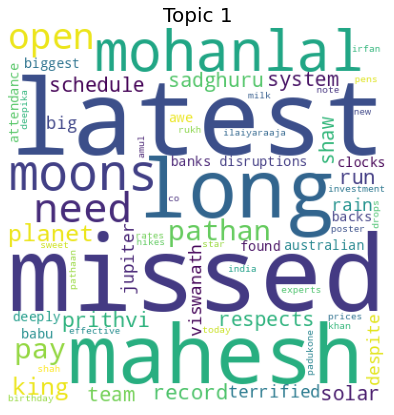

In [ ]:
show_wordcloud(to[0],'Topic 1')

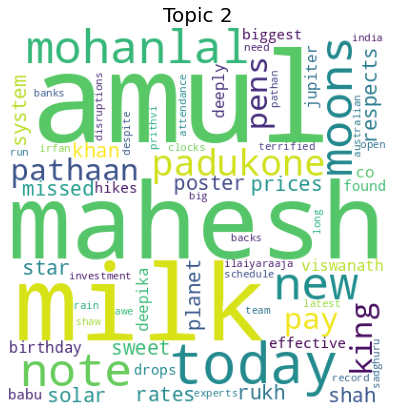

In [ ]:
show_wordcloud(to[1],'Topic 2')

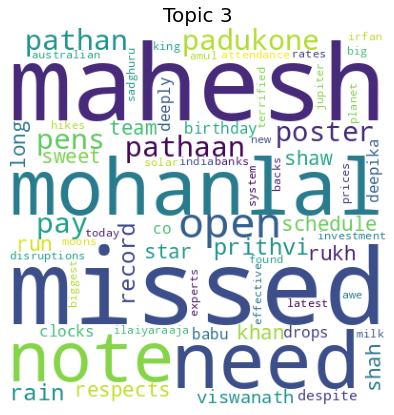

In [ ]:
show_wordcloud(to[2],'Topic 3')

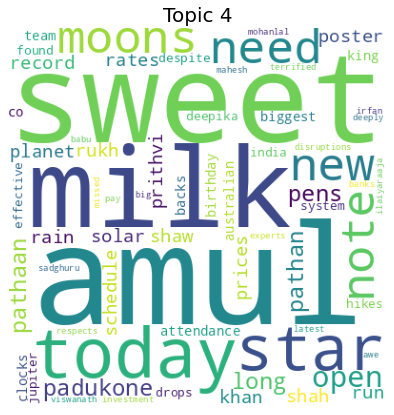

In [ ]:
show_wordcloud(to[3],'Topic 4')